# MVP -- Agricultural Drone Flight Control RL (MuJoCo)

**Purpose of this notebook:** a runnable, minimal version of the environment so the team can see how the RL problem is framed, using a real physics simulation, before we invest time training a real agent. Nothing here is trained -- this proves the physics/reward loop works and shows exactly the control problem an RL policy would need to solve.

## The problem
A drone needs to fly at a fixed altitude directly above a crop row, staying on course despite wind gusts, to scan/monitor the crop below. This is a **continuous control** problem (motor thrusts, physical dynamics) -- which is why we use MuJoCo (a physics engine) instead of a simple grid environment.

## Physics model
We use the **Skydio X2** quadrotor model from Google DeepMind's `mujoco_menagerie` (Apache-2.0, actively maintained) -- a real, physically-accurate drone description (4 rotors, mass, inertia), not something we modeled ourselves.

## RL formulation
- **State**: altitude error, lateral offset from the crop row centerline, orientation (quaternion), linear/angular velocity, current wind disturbance.
- **Action**: thrust delta for each of the 4 rotors (continuous).
- **Reward**: penalizes altitude error, lateral drift, tilt, and large actions; a bonus for finishing the row, a penalty for crashing.
- A random wind gust continuously pushes the drone sideways -- this is the disturbance the policy has to learn to reject.

## What this notebook shows
1. The environment itself (`AgroDroneEnv`), fully commented.
2. Two **hand-coded, non-learned** baseline controllers, used only to sanity-check the environment:
   - **altitude-hold**: uniform thrust correction on all 4 rotors. Holds altitude well but does nothing about lateral wind drift -- this is deliberately "the naive baseline" that shows the gap a trained policy needs to close.
   - **random**: sanity-check lower bound -- expect a fast crash.
3. Trajectory plots (altitude, lateral drift, reward).

**Note on 3D rendering:** if MuJoCo's OpenGL renderer isn't available in your environment (common on headless machines), the physics still runs fine -- we just plot the trajectory with matplotlib instead of a 3D view. In Colab, add `!pip install mujoco` and the `Renderer`/`mediapy` combo works for a real rendered video if you want that later.

**Next step (not in this MVP):** train PPO or SAC (e.g. with CleanRL, confirmed Gymnasium-compatible with custom environments) to actually solve station-keeping + forward progress.

In [1]:
# If running in Google Colab (headless, no display), uncomment these first:
# !pip install -q mujoco gymnasium
# !apt-get install -y libgl1-mesa-dev libgl1-mesa-glx libglx-mesa0 libosmesa6-dev software-properties-common -qq
# !git clone --depth 1 --filter=blob:none --sparse https://github.com/google-deepmind/mujoco_menagerie.git && cd mujoco_menagerie && git sparse-checkout set skydio_x2
#
# If running LOCALLY on Linux/WSL/VS Code and you hit "Default framebuffer is
# not complete" below, run this in a terminal BEFORE starting the notebook,
# then fully restart the kernel (env vars set mid-notebook can be too late --
# the kernel process may have already loaded a conflicting GL library):
#   sudo apt-get install -y libosmesa6-dev libgl1-mesa-dev libglx-mesa0
#   pip install --force-reinstall --no-cache-dir mujoco
#   export MUJOCO_GL=osmesa
#   export PYOPENGL_PLATFORM=osmesa

import os

DRONE_DIR = "mujoco_menagerie/skydio_x2"  # adjust if you cloned elsewhere

# Minimal custom scene: the drone (x2.xml, unmodified) + a plain flat floor
# and sky, no heavy texture assets (the official scene.xml's gradient skybox
# + checker floor is the likely cause of the earlier multi-minute hang).
_SIMPLE_SCENE = """<mujoco model="Skydio X2 scene (simple)">
  <include file="x2.xml"/>
  <visual>
    <headlight diffuse="0.6 0.6 0.6" ambient="0.3 0.3 0.3" specular="0 0 0"/>
  </visual>
  <asset>
    <texture type="skybox" builtin="flat" rgb1="0.55 0.75 0.9" width="2" height="2"/>
  </asset>
  <worldbody>
    <light pos="0 0 3" dir="0 0 -1" directional="true"/>
    <geom name="floor" size="0 0 0.05" type="plane" rgba="0.45 0.6 0.35 1"/>
  </worldbody>
</mujoco>"""
with open(os.path.join(DRONE_DIR, "x2_simple_scene.xml"), "w") as f:
    f.write(_SIMPLE_SCENE)

XML_PATH = os.path.join(DRONE_DIR, "x2_simple_scene.xml")

# MUJOCO_GL alone wasn't enough for you -- PyOpenGL also needs
# PYOPENGL_PLATFORM set to the same backend, otherwise it can initialize a
# conflicting GLX/X11 context alongside OSMesa's software context, which is
# almost certainly what caused "Default framebuffer is not complete" (a known
# Mesa issue when both get linked into the same process).
os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = "osmesa"
try:
    import mujoco
    MUJOCO_RENDER_AVAILABLE = True
    print("mujoco imported successfully with MUJOCO_GL=osmesa.")
except Exception as e:
    os.environ.pop("MUJOCO_GL", None)
    os.environ.pop("PYOPENGL_PLATFORM", None)
    import sys
    for mod in [m for m in list(sys.modules) if m.startswith("mujoco")]:
        del sys.modules[mod]
    import mujoco
    MUJOCO_RENDER_AVAILABLE = False
    print("Could not import mujoco with MUJOCO_GL=osmesa:", repr(e))
    print("Physics still works fine -- use the matplotlib animation below for a visual preview.")

Could not import mujoco with MUJOCO_GL=osmesa: AttributeError("'NoneType' object has no attribute 'glGetError'")
Physics still works fine -- use the matplotlib animation below for a visual preview.


In [2]:
"""
AgroDroneEnv -- minimal MVP Gymnasium environment for the agricultural
crop-row flight-control RL project idea.

Physics: MuJoCo Skydio X2 quadrotor model (Google DeepMind mujoco_menagerie,
Apache-2.0 license, https://github.com/google-deepmind/mujoco_menagerie).

Task: the agent controls 4 rotor thrusts to keep the drone flying at a
target altitude directly above a simulated crop row (the world x-axis),
while a random wind gust keeps pushing it sideways, and to make progress
down the row.

This is a bare-bones, UNTRAINED environment -- its purpose is to demonstrate
the project idea to teammates: the state/action/reward design and a working
physics simulation you can actually run and inspect. Training a real policy
(PPO/SAC via Stable-Baselines3) is the next step, not part of this MVP.
"""
import numpy as np
import mujoco
import gymnasium as gym
from gymnasium import spaces


class AgroDroneEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, xml_path, target_altitude=1.2, field_length=20.0,
                 wind_strength=0.6, max_steps=500, seed=None):
        super().__init__()
        self.model = mujoco.MjModel.from_xml_path(xml_path)
        self.data = mujoco.MjData(self.model)

        self.target_altitude = target_altitude
        self.field_length = field_length   # crop row length in meters (+x direction)
        self.wind_strength = wind_strength
        self.max_steps = max_steps

        # hover thrust per rotor, read straight from the model's own "hover" keyframe
        self.hover_ctrl = self.model.key_ctrl[0].copy()
        self.ctrl_range = self.model.actuator_ctrlrange.copy()  # shape (4, 2)

        # action = delta thrust per rotor, centered on hover (so action=0 means "hold hover")
        self.action_space = spaces.Box(low=-3.0, high=3.0, shape=(4,), dtype=np.float32)

        # observation: [alt_error, lateral_offset, quat(4), linvel(3), angvel(3), wind(2)]
        obs_dim = 1 + 1 + 4 + 3 + 3 + 2
        self.observation_space = spaces.Box(low=-np.inf, high=np.inf, shape=(obs_dim,), dtype=np.float32)

        self._rng = np.random.default_rng(seed)
        self._steps = 0
        self._wind = np.zeros(2)

    # ------------------------------------------------------------------
    def _get_obs(self):
        pos = self.data.qpos[0:3]
        quat = self.data.qpos[3:7]
        linvel = self.data.qvel[0:3]
        angvel = self.data.qvel[3:6]
        alt_error = pos[2] - self.target_altitude
        lateral_offset = pos[1]  # crop row centerline is y=0
        return np.concatenate([
            [alt_error, lateral_offset], quat, linvel, angvel, self._wind
        ]).astype(np.float32)

    def _apply_wind(self):
        # slowly-varying random lateral/vertical gust, applied as a translational
        # force at the drone's body -- this is the disturbance the policy must reject
        self._wind += self._rng.normal(0, 0.05, size=2)
        self._wind = np.clip(self._wind, -self.wind_strength, self.wind_strength)
        self.data.xfrc_applied[1, 0] = 0.0
        self.data.xfrc_applied[1, 1] = self._wind[0]         # lateral (y) force
        self.data.xfrc_applied[1, 2] = self._wind[1] * 0.3   # small vertical gust

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        mujoco.mj_resetDataKeyframe(self.model, self.data, 0)
        # small random start offset so every episode is slightly different
        self.data.qpos[1] += self._rng.uniform(-0.15, 0.15)
        self.data.qpos[2] = self.target_altitude + self._rng.uniform(-0.1, 0.1)
        self._steps = 0
        self._wind = np.zeros(2)
        mujoco.mj_forward(self.model, self.data)
        return self._get_obs(), {}

    def step(self, action):
        action = np.clip(action, self.action_space.low, self.action_space.high)
        ctrl = np.clip(self.hover_ctrl + action, self.ctrl_range[:, 0], self.ctrl_range[:, 1])
        self.data.ctrl[:] = ctrl

        self._apply_wind()
        mujoco.mj_step(self.model, self.data)
        self._steps += 1

        pos = self.data.qpos[0:3]
        quat = self.data.qpos[3:7]
        alt_error = pos[2] - self.target_altitude
        lateral_offset = pos[1]

        # tilt angle from quaternion (how far from level flight -- 0 = level, pi/2 = sideways)
        up_z = 1 - 2 * (quat[1] ** 2 + quat[2] ** 2)
        tilt = np.arccos(np.clip(up_z, -1.0, 1.0))

        action_cost = 0.01 * np.sum(np.square(action))
        reward = (
            -1.0 * abs(alt_error)
            -1.0 * abs(lateral_offset)
            -0.5 * tilt
            -action_cost
            +0.05  # small "still flying" bonus per step
        )

        crashed = bool(pos[2] < 0.08 or tilt > 1.2)   # hit ground or flipped over
        finished_row = bool(pos[0] >= self.field_length)
        truncated = self._steps >= self.max_steps
        terminated = crashed or finished_row

        if crashed:
            reward -= 20.0
        if finished_row:
            reward += 20.0

        info = {"crashed": crashed, "finished_row": finished_row,
                "alt_error": float(alt_error), "lateral_offset": float(lateral_offset)}
        return self._get_obs(), reward, terminated, truncated, info


# ---------------------------------------------------------------------------
# Two simple, HAND-CODED (not learned) baseline controllers, used only to
# demonstrate the environment. Neither "solves" the task -- that's the point:
# they show exactly the gap a trained RL policy would need to close.
# ---------------------------------------------------------------------------

def random_action(obs, action_space, rng):
    """Pure random control -- expect a quick crash. Sanity-check baseline."""
    return action_space.sample() * 0.3  # scaled down so it doesn't flip instantly


def altitude_hold_action(obs, kp_alt=2.2, kd_alt=1.4):
    """Uniform thrust correction on all 4 rotors -- holds altitude well
    (no differential thrust, so it stays level) but does nothing about
    lateral wind drift or forward progress along the row. This is the
    'naive baseline' that motivates why you need a real (learned) policy."""
    alt_error, vz = obs[0], obs[8]
    lift = -kp_alt * alt_error - kd_alt * vz
    return np.array([lift, lift, lift, lift], dtype=np.float32)


## Run the baseline controllers and compare

In [3]:
import numpy as np
import matplotlib.pyplot as plt

def run(action_fn, seed=1, max_steps=400, use_random=False):
    env = AgroDroneEnv(XML_PATH, field_length=8.0, max_steps=max_steps, seed=seed)
    obs, info = env.reset()
    rng = np.random.default_rng(seed)
    rows = []
    for t in range(max_steps):
        action = random_action(obs, env.action_space, rng) if use_random else action_fn(obs)
        obs, r, term, trunc, info = env.step(action)
        rows.append({"t": t, "alt": env.data.qpos[2], "lat": env.data.qpos[1],
                      "x": env.data.qpos[0], "reward": r})
        if term or trunc:
            break
    return rows

rows_hold = run(altitude_hold_action, use_random=False)
rows_rand = run(None, use_random=True)

print(f"altitude-hold survived {len(rows_hold)} steps ({len(rows_hold)*0.01:.1f}s simulated)")
print(f"random policy survived {len(rows_rand)} steps ({len(rows_rand)*0.01:.1f}s simulated)")

altitude-hold survived 400 steps (4.0s simulated)
random policy survived 139 steps (1.4s simulated)


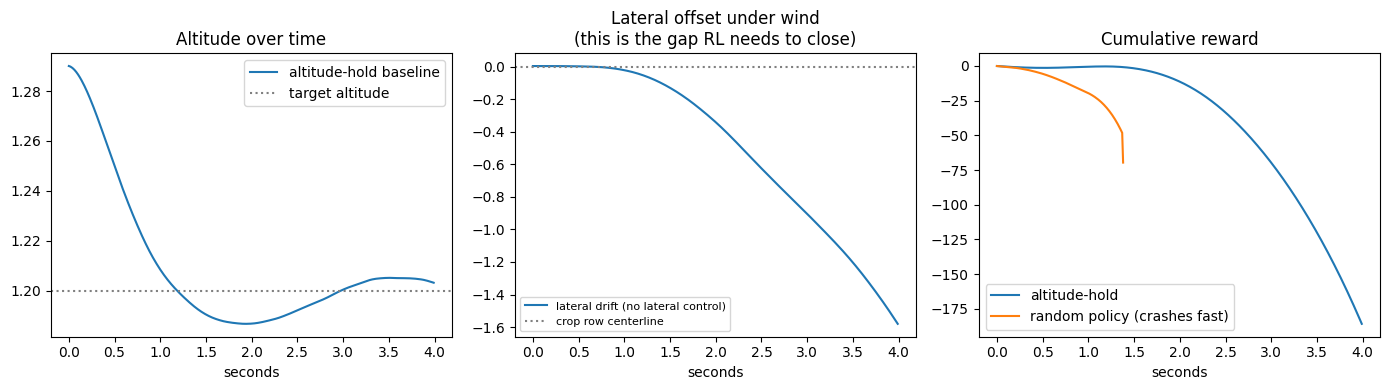

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
t_hold = [r["t"] * 0.01 for r in rows_hold]
t_rand = [r["t"] * 0.01 for r in rows_rand]

axes[0].plot(t_hold, [r["alt"] for r in rows_hold], label="altitude-hold baseline")
axes[0].axhline(1.2, color="gray", ls=":", label="target altitude")
axes[0].set_title("Altitude over time"); axes[0].set_xlabel("seconds"); axes[0].legend()

axes[1].plot(t_hold, [r["lat"] for r in rows_hold], label="lateral drift (no lateral control)")
axes[1].axhline(0, color="gray", ls=":", label="crop row centerline")
axes[1].set_title("Lateral offset under wind\n(this is the gap RL needs to close)")
axes[1].set_xlabel("seconds"); axes[1].legend(fontsize=8)

axes[2].plot(t_hold, np.cumsum([r["reward"] for r in rows_hold]), label="altitude-hold")
axes[2].plot(t_rand, np.cumsum([r["reward"] for r in rows_rand]), label="random policy (crashes fast)")
axes[2].set_title("Cumulative reward"); axes[2].set_xlabel("seconds"); axes[2].legend()

plt.tight_layout()
plt.show()

## Visual preview

Two options below:

1. **Matplotlib animation (always works, no GPU/display needed)** -- a lightweight top-view + side-view animation built straight from the simulated trajectory. This is the reliable option -- use it if the 3D render (option 2) fails, which is common on headless/local machines without proper OpenGL drivers.
2. **Real 3D MuJoCo render (Colab-friendly)** -- an actual rendered view of the Skydio X2 model using MuJoCo's built-in camera. Needs a working OpenGL backend (EGL/OSMesa); this is usually available in Colab but not guaranteed on every local setup.

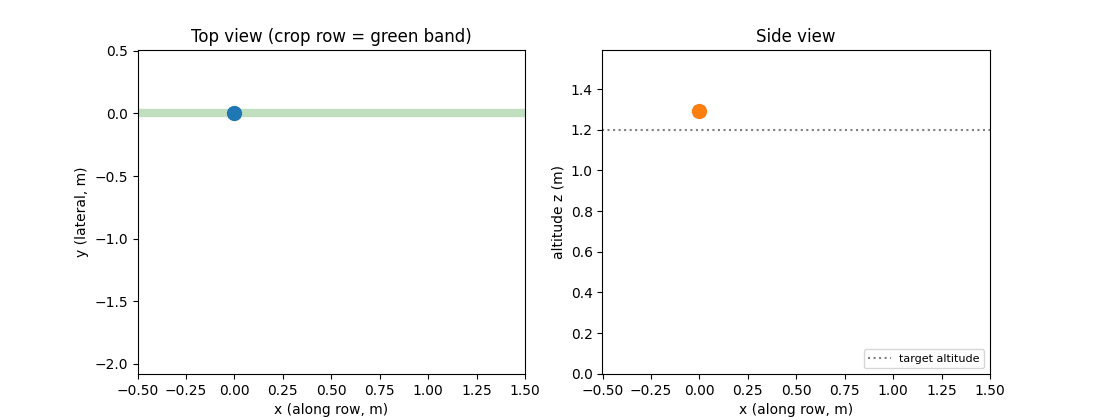

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image as IPImage

env = AgroDroneEnv(XML_PATH, field_length=8.0, max_steps=400, seed=1)
obs, info = env.reset()
xs, ys, zs = [], [], []
for t in range(400):
    action = altitude_hold_action(obs)
    obs, r, term, trunc, info = env.step(action)
    xs.append(env.data.qpos[0]); ys.append(env.data.qpos[1]); zs.append(env.data.qpos[2])
    if term or trunc:
        break
xs, ys, zs = np.array(xs), np.array(ys), np.array(zs)

fig, (ax_top, ax_side) = plt.subplots(1, 2, figsize=(11, 4.2))
ax_top.set_xlim(xs.min() - 0.5, max(xs.max(), 1) + 0.5); ax_top.set_ylim(ys.min() - 0.5, ys.max() + 0.5)
ax_top.axhline(0, color="green", lw=6, alpha=0.25, zorder=0)
ax_top.set_title("Top view (crop row = green band)"); ax_top.set_xlabel("x (along row, m)"); ax_top.set_ylabel("y (lateral, m)")
top_dot, = ax_top.plot([], [], "o", color="tab:blue", ms=10)
top_trail, = ax_top.plot([], [], "-", color="tab:blue", alpha=0.4)

ax_side.set_xlim(xs.min() - 0.5, max(xs.max(), 1) + 0.5); ax_side.set_ylim(0, max(zs.max(), env.target_altitude) + 0.3)
ax_side.axhline(env.target_altitude, color="gray", ls=":", label="target altitude")
ax_side.set_title("Side view"); ax_side.set_xlabel("x (along row, m)"); ax_side.set_ylabel("altitude z (m)")
side_dot, = ax_side.plot([], [], "o", color="tab:orange", ms=10)
side_trail, = ax_side.plot([], [], "-", color="tab:orange", alpha=0.4)
ax_side.legend(loc="lower right", fontsize=8)

def update(i):
    top_dot.set_data([xs[i]], [ys[i]])
    top_trail.set_data(xs[:i+1], ys[:i+1])
    side_dot.set_data([xs[i]], [zs[i]])
    side_trail.set_data(xs[:i+1], zs[:i+1])
    return top_dot, top_trail, side_dot, side_trail

frame_idx = range(0, len(xs), 3)  # thin out for a reasonably sized gif
ani = animation.FuncAnimation(fig, update, frames=frame_idx, blit=True, interval=60)
ani.save("drone_preview.gif", writer=animation.PillowWriter(fps=15))
plt.close(fig)
IPImage(filename="drone_preview.gif")

In [6]:
# --- Option 2: real 3D MuJoCo render ---
from IPython.display import Image as IPImage, display
import traceback

if not MUJOCO_RENDER_AVAILABLE:
    print("Skipping 3D render -- no working OpenGL backend was found in this environment (see setup cell).")
    print("Use the matplotlib animation above, or run this notebook in Colab for the real render.")
else:
    try:
        from PIL import Image

        render_env = AgroDroneEnv(XML_PATH, field_length=8.0, max_steps=100, seed=1)
        obs, info = render_env.reset()
        renderer = mujoco.Renderer(render_env.model, height=240, width=320)

        frames = []
        for t in range(100):
            action = altitude_hold_action(obs)
            obs, r, term, trunc, info = render_env.step(action)
            renderer.update_scene(render_env.data, camera="track")  # "track" camera is defined in x2.xml
            frames.append(Image.fromarray(renderer.render()))
            if t % 20 == 0:
                print(f"  rendered frame {t}/100", flush=True)
            if term or trunc:
                break

        frames[0].save("drone_render.gif", save_all=True, append_images=frames[1:], duration=40, loop=0)
        print(f"Rendered {len(frames)} frames total.")
        display(IPImage(filename="drone_render.gif"))
    except Exception:
        print("3D render failed -- full traceback below (send me this if you need help debugging):")
        traceback.print_exc()
        print()
        print("Use the matplotlib animation above as the visual preview instead.")

Skipping 3D render -- no working OpenGL backend was found in this environment (see setup cell).
Use the matplotlib animation above, or run this notebook in Colab for the real render.


## What to notice (talking points for the team meeting)

- **Altitude control is easy** -- a simple uniform-thrust correction holds altitude almost perfectly (this doesn't need learning, basic physics/PD control handles it).
- **Lateral station-keeping is the real problem** -- with zero lateral correction, wind pushes the drone steadily off the crop row. A trained policy needs to correct for this while still moving forward, which requires coordinated differential thrust across the 4 rotors (roll/pitch control) -- much harder to hand-tune than it looks (we tried a hand-coded PD controller for this and it went unstable, which is itself a good illustration of why this needs RL rather than manual tuning).
- **Random actions crash almost immediately** -- confirms the environment's termination/crash logic is working and gives us a sanity-check lower bound.
- Physics steps at `dt=0.01s`, so a few hundred steps already cover multiple seconds of flight -- training should be feasible on a single Colab GPU session (Fetch-arm tasks of similar scale typically converge in 2-6 hours with SB3).

## Ecosystem note
There's no ready-made "Gym for agricultural drones" -- this environment is genuinely custom, built on top of DeepMind's maintained Skydio X2 physics model. For the training algorithm itself, we'd use **CleanRL** (actively maintained, confirmed to work with any custom registered Gymnasium environment, not just Atari).